# Project A: Fine-tuned small model vs. prompted frontier model for banking complaint routing

**Question:** for a narrow, high-volume banking task, does a small open model fine-tuned with QLoRA match or beat a well-prompted frontier model on accuracy, and what does each cost per 1,000 complaints?

**Task:** route a customer complaint about a checking or savings account to its *issue* category, using real complaint narratives from the public [CFPB Consumer Complaint Database](https://www.consumerfinance.gov/data-research/consumer-complaints/).

**Three systems, one held-out test set:**

| System | What it is |
| --- | --- |
| `small_base_fewshot` | Small open model (default Qwen2.5-1.5B-Instruct), prompted with the label list and one example per label. No training. |
| `small_finetuned` | The same small model after QLoRA supervised fine-tuning. Short prompt: label list only. |
| `frontier_fewshot` | A frontier model via API, same few-shot prompt as the base small model. |

**How to run:** Colab GPU runtime (T4 is enough). Run top to bottom. Expect roughly 10 min for data download and filtering, 5–10 min for the frontier baseline, and 20–40 min for fine-tuning and evaluation. Predictions are cached in `results/`, so a disconnect doesn't cost you finished steps.

**One caveat to keep in mind:** in the CFPB data, consumers pick the issue themselves when filing. Labels are therefore noisy, which caps achievable accuracy for every system. That's realistic: bank ticket labels are noisy too. Mention it in your write-up.

In [1]:
!pip install -q -U transformers peft accelerate bitsandbytes datasets scikit-learn anthropic

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:

# !pip install datasets
# !pip install -U bitsandbytes>=0.46.1

## 1. Configuration

In [3]:
# ---- Data ----
SEED = 42
PRODUCT = "Checking or savings account"  # CFPB product to focus on
MIN_DATE = "2023-01-01"                  # recent complaints only: CFPB's issue taxonomy has changed over the years
TOP_K_ISSUES = 8                         # the K most common issues become the labels
MAX_PER_CLASS = 800                      # cap per label to limit class imbalance
N_TEST = 400                             # held-out test set, used once for the final comparison
N_VAL = 200                              # validation set, for the fine-tuned model's eval loss
MAX_CHARS = 1200                         # truncate long narratives (keeps prompts short and cheap)

# ---- Models ----
SMALL_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"  # ungated, Apache 2.0. Try "Qwen/Qwen2.5-3B-Instruct" next.
# The big model to compare against:
#   "gemini"      -> free API key from Google AI Studio (https://aistudio.google.com/apikey)
#   "anthropic"   -> paid API key from the Claude Console
#   "local_large" -> no key: a 7B open model on the same T4 (not a frontier model, but a fair "bigger model" baseline)
BASELINE = "local_large"
GEMINI_MODEL = "gemini-flash-latest"        # or a specific model name from AI Studio's model list
ANTHROPIC_MODEL = "claude-sonnet-5-5"
LARGE_LOCAL_MODEL = "Qwen/Qwen2.5-7B-Instruct"
API_SECONDS_BETWEEN_CALLS = 6.0             # pause between API calls to stay under free-tier per-minute limits

# ---- LoRA / training ----
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
LR, EPOCHS = 2e-4, 1
BATCH, GRAD_ACCUM = 4, 4   # effective batch size 16
MAX_LEN = 768              # max tokens per training example
GEN_BATCH_SHORT, GEN_BATCH_FEWSHOT = 16, 8

GEMINI_MODEL = "gemini-3.6-flash"   # name a specific model so the price below matches it
FRONTIER_PRICE_IN_PER_M = 1.50      # USD per 1M input tokens  (Gemini 3.6 Flash, standard price)
FRONTIER_PRICE_OUT_PER_M = 7.50     # USD per 1M output tokens (includes thinking tokens)
GPU_PRICE_PER_HOUR = 0.526          # USD per hour, AWS g4dn.xlarge (1x T4), on-demand

DATA_DIR, OUT_DIR, RESULTS_DIR = "data", "outputs", "results"

In [4]:
import os, re, json, time, random, getpass, subprocess
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

for d in (DATA_DIR, OUT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

assert torch.cuda.is_available(), "No GPU: switch the Colab runtime to GPU (T4)."
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


## 2. Data: download and filter CFPB complaints

In [5]:
import io, zipfile

# CFPB stopped publishing narratives in its main download on 14 Aug 2026. The narratives that were
# published before then are in CFPB's FOIA Reading Room archive, split into ZIP files by date range.
ARCHIVES = [
    "https://files.consumerfinance.gov/f/documents/CCDB_Export_4_November_2022_through_August_2023.zip",
    "https://files.consumerfinance.gov/f/documents/CCDB_Export_5_September_2023_through_March_2024.zip",
]
CACHE = f"{DATA_DIR}/archive_{re.sub(r'[^a-z]+', '_', PRODUCT.lower())}.parquet"

def column_map(header):
    # Find the columns we need by name pattern; spelling and casing vary between CFPB files
    norm = lambda s: re.sub(r"[^a-z]+", " ", str(s).lower()).strip()
    def find(*keywords):
        hits = [c for c in header if all(k in norm(c) for k in keywords)]
        if not hits:
            raise KeyError(f"No column matching {keywords}. Columns in this file: {header}")
        return min(hits, key=lambda c: len(str(c)))   # 'Issue' rather than 'Sub-issue'
    return {"date": find("date", "received"), "product": find("product"), "issue": find("issue"),
            "text": find("narrative"), "id": find("complaint", "id")}

def iter_tables(zf, name=""):
    # Yield DataFrames with standard columns from every CSV/Excel file in a ZIP (including nested ZIPs)
    for m in zf.namelist():
        low = m.lower()
        if low.endswith(".zip"):
            yield from iter_tables(zipfile.ZipFile(io.BytesIO(zf.read(m))), m)
        elif low.endswith(".csv"):
            with zf.open(m) as f:
                col = column_map(pd.read_csv(f, nrows=0).columns.tolist())
            print(f"  {m}: using {col}")
            with zf.open(m) as f:
                for chunk in pd.read_csv(f, usecols=list(col.values()), dtype=str, chunksize=250_000):
                    yield chunk.rename(columns={v: k for k, v in col.items()})
        elif low.endswith((".xlsx", ".xls")):
            x = pd.read_excel(io.BytesIO(zf.read(m)), dtype=str)
            col = column_map(x.columns.tolist())
            print(f"  {m}: using {col}")
            yield x[list(col.values())].rename(columns={v: k for k, v in col.items()})

if os.path.exists(CACHE):
    raw = pd.read_parquet(CACHE)
else:
    parts, products_seen = [], set()
    for url in ARCHIVES:
        path = f"{DATA_DIR}/{url.rsplit('/', 1)[-1]}"
        if not os.path.exists(path):
            subprocess.run(["wget", "-q", "--show-progress", "-O", path, url], check=True)
        zf = zipfile.ZipFile(path)
        print(path, "contains:", zf.namelist())
        found = False
        for chunk in iter_tables(zf):
            found = True
            products_seen.update(chunk["product"].dropna().unique())
            c = chunk[(chunk["product"] == PRODUCT) & chunk["text"].notna()]
            c = c[pd.to_datetime(c["date"], errors="coerce", format="mixed") >= pd.Timestamp(MIN_DATE)]
            parts.append(c)
        if not found:
            raise ValueError(f"No CSV or Excel file inside {path}. Paste the 'contains:' line above into the chat.")
    raw = pd.concat(parts, ignore_index=True).drop_duplicates(subset="id")
    if raw.empty:
        raise ValueError(f"No rows matched PRODUCT={PRODUCT!r}. Products found: {sorted(products_seen)}")
    raw.to_parquet(CACHE)

print(f"{len(raw):,} complaints with narratives for '{PRODUCT}' since {MIN_DATE}")
raw["issue"].value_counts().head(15)


     0K .......... .......... .......... .......... ..........  0% 1.22M 90s
    50K .......... .......... .......... .......... ..........  0% 1.51M 81s
   100K .......... .......... .......... .......... ..........  0% 2.01M 72s
   150K .......... .......... .......... .......... ..........  0% 1.88M 69s
   200K .......... .......... .......... .......... ..........  0% 1.39M 71s
   250K .......... .......... .......... .......... ..........  0% 2.83M 66s
   300K .......... .......... .......... .......... ..........  0% 4.96M 59s
   350K .......... .......... .......... .......... ..........  0% 27.0M 52s
   400K .......... .......... .......... .......... ..........  0% 25.7M 47s
   450K .......... .......... .......... .......... ..........  0% 5.84M 44s
   500K .......... .......... .......... .......... ..........  0% 18.9M 41s
   550K .......... .......... .......... .......... ..........  0% 1.48M 43s
   600K .......... .......... .......... .......... ..........  0% 53.9M 40

data/CCDB_Export_4_November_2022_through_August_2023.zip contains: ['CCDB_Export_4_November_2022_through_August_2023.csv']
  CCDB_Export_4_November_2022_through_August_2023.csv: using {'date': 'Date received', 'product': 'Product', 'issue': 'Issue', 'text': 'Consumer complaint narrative', 'id': 'Complaint ID'}



     0K .......... .......... .......... .......... ..........  0% 5.39M 18s
    50K .......... .......... .......... .......... ..........  0% 10.0M 14s
   100K .......... .......... .......... .......... ..........  0% 10.5M 12s
   150K .......... .......... .......... .......... ..........  0% 22.3M 10s
   200K .......... .......... .......... .......... ..........  0% 26.0M 9s
   250K .......... .......... .......... .......... ..........  0% 10.4M 9s
   300K .......... .......... .......... .......... ..........  0% 14.0M 9s
   350K .......... .......... .......... .......... ..........  0% 7.87M 9s
   400K .......... .......... .......... .......... ..........  0%  177M 8s
   450K .......... .......... .......... .......... ..........  0%  162M 7s
   500K .......... .......... .......... .......... ..........  0%  178M 7s
   550K .......... .......... .......... .......... ..........  0%  246M 6s
   600K .......... .......... .......... .......... ..........  0% 1.57M 10s
   650

data/CCDB_Export_5_September_2023_through_March_2024.zip contains: ['CCDB_Export_5_September_2023_through_March_2024.csv']
  CCDB_Export_5_September_2023_through_March_2024.csv: using {'date': 'Date received', 'product': 'Product', 'issue': 'Issue', 'text': 'Consumer complaint narrative', 'id': 'Complaint ID'}
34,641 complaints with narratives for 'Checking or savings account' since 2023-01-01


issue
Managing an account                                                                 19183
Closing an account                                                                   5108
Problem with a lender or other company charging your account                         4527
Opening an account                                                                   3183
Problem caused by your funds being low                                               2473
Incorrect information on your report                                                   44
Problem with a company's investigation into an existing problem                        33
Improper use of your report                                                            29
Problem with fraud alerts or security freezes                                          27
Credit monitoring or identity theft protection services                                22
Problem with a credit reporting company's investigation into an existing problem       11
Unab

In [6]:
raw.head()

,date,product,issue,text,id
0,2023-04-21,Checking or savings account,Managing an account,In XX/XX/2023 a third party deposited a check ...,6872134
1,2023-07-07,Checking or savings account,Closing an account,"On XX/XX/2023, I went to open an individual ac...",7219500
2,2023-03-11,Checking or savings account,Problem with a lender or other company chargin...,Somebody created an fraud account with XXXX XX...,6681481
3,2023-03-11,Checking or savings account,Problem with a lender or other company chargin...,I pay for parking and I thought the parking pe...,6681372
4,2023-03-11,Checking or savings account,Managing an account,Wachovia bank incorrect charges,6681310


In [7]:
df = raw.rename(columns={"issue": "label"})[["id", "text", "label"]].copy()
df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
df = df[df["text"].str.len() >= 50].drop_duplicates(subset="text")   # drop near-empty and duplicate narratives

LABELS = df["label"].value_counts().head(TOP_K_ISSUES).index.tolist()
df = df[df["label"].isin(LABELS)]
df = df.sample(frac=1, random_state=SEED).groupby("label").head(MAX_PER_CLASS).reset_index(drop=True)

trainval, test = train_test_split(df, test_size=N_TEST, stratify=df["label"], random_state=SEED)
train, val = train_test_split(trainval, test_size=N_VAL, stratify=trainval["label"], random_state=SEED)
test = test.reset_index(drop=True)

# Leakage check: no narrative appears in more than one split
assert not set(train.text) & set(test.text) and not set(val.text) & set(test.text)

print(f"Labels ({len(LABELS)}):", *LABELS, sep="\n  - ")
print(f"\ntrain={len(train):,}  val={len(val):,}  test={len(test):,}")
pd.DataFrame({"train": train.label.value_counts(), "test": test.label.value_counts()})

Labels (8):
  - Managing an account
  - Closing an account
  - Problem with a lender or other company charging your account
  - Opening an account
  - Problem caused by your funds being low
  - Incorrect information on your report
  - Problem with a company's investigation into an existing problem
  - Improper use of your report

train=3,502  val=200  test=400


,train,test
label,,
Closing an account,683,78
Improper use of your report,23,3
Incorrect information on your report,36,4
Managing an account,683,78
Opening an account,683,78
Problem caused by your funds being low,683,78
Problem with a company's investigation into an existing problem,28,3
Problem with a lender or other company charging your account,683,78


## 3. Prompts, label parsing and evaluation helpers

In [8]:
SYSTEM = ("You are a complaint-routing assistant at a retail bank. Classify the customer's complaint "
          "into exactly one issue category from the list. Reply with the category name only, copied exactly.")
LABEL_LIST = "\n".join(f"- {l}" for l in LABELS)

def truncate(t, n=MAX_CHARS):
    return t if len(t) <= n else t[:n].rsplit(" ", 1)[0] + " ..."

# One example per label for few-shot prompts, taken from the TRAINING set only (about 400 characters each)
fewshot = (train.assign(d=(train.text.str.len() - 400).abs())
                .sort_values("d").groupby("label").head(1))
FEWSHOT_BLOCK = "\n\n".join(f'Complaint: "{truncate(r.text, 500)}"\nCategory: {r.label}'
                            for r in fewshot.itertuples())

def user_prompt(text, few_shot):
    parts = [f"Categories:\n{LABEL_LIST}"]
    if few_shot:
        parts.append(f"Examples:\n\n{FEWSHOT_BLOCK}")
    parts.append(f'Complaint: "{truncate(text)}"\nCategory:')
    return "\n\n".join(parts)

def _norm(s):
    return re.sub(r"[^a-z0-9]+", " ", s.lower()).strip()
NORM2LABEL = {_norm(l): l for l in LABELS}

def parse_label(output):
    # Exact match on the first line, then the longest label contained anywhere in the output; else None (invalid)
    output = output if isinstance(output, str) else ""
    first = _norm(output.strip().split("\n")[0]) if output.strip() else ""
    if first in NORM2LABEL:
        return NORM2LABEL[first]
    full = _norm(output)
    for n in sorted(NORM2LABEL, key=len, reverse=True):
        if n and n in full:
            return NORM2LABEL[n]
    return None

def bootstrap_ci(y_true, y_pred, n=1000):
    rng = np.random.default_rng(SEED)
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    scores = []
    for _ in range(n):
        s = rng.integers(0, len(y_true), len(y_true))
        scores.append(f1_score(y_true[s], y_pred[s], labels=LABELS, average="macro", zero_division=0))
    return np.percentile(scores, [2.5, 97.5])

RESULTS = {}

def record(name, preds_df, sec_per_item, cost_per_1k, extra=None):
    preds_df = preds_df.copy()
    preds_df["pred"] = [parse_label(o) or "INVALID" for o in preds_df["output"]]
    y_true, y_pred = preds_df["label"].tolist(), preds_df["pred"].tolist()
    lo, hi = bootstrap_ci(y_true, y_pred)
    RESULTS[name] = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "macro_f1_95ci": f"{lo:.3f}–{hi:.3f}",
        "invalid_rate": float(np.mean([p == "INVALID" for p in y_pred])),
        "sec_per_item": sec_per_item,
        "cost_per_1k_usd": cost_per_1k,
        **(extra or {}),
    }
    preds_df.to_csv(f"{RESULTS_DIR}/preds_{name}.csv", index=False)
    print(name, {k: (round(v, 4) if isinstance(v, float) else v) for k, v in RESULTS[name].items()})
    return preds_df

def cached(name):
    p = f"{RESULTS_DIR}/preds_{name}.csv"
    return pd.read_csv(p) if os.path.exists(p) else None

print(user_prompt(test.text[0], few_shot=False)[:1500])

Categories:
- Managing an account
- Closing an account
- Problem with a lender or other company charging your account
- Opening an account
- Problem caused by your funds being low
- Incorrect information on your report
- Problem with a company's investigation into an existing problem
- Improper use of your report

Complaint: "CitiBank NA repeatedly sent me a Member Advantage Miles Checking with a reward if I complete certain actions in a given timeframe. The reward was XXXX American Advantage Bonus points WITHIN 30 CALENDAR DAYS FROM THE DATE YOU COMPLETE ALL REQUIRED ACTIVITIES. The time period allowed to complete the activities was up to 90 days. I opened offer account on XX/XX/XXXX and FULFILLED THE REQUIRED ACTIVITIES ON XX/XX/XXXX. On XX/XX/XXXX, I contacted CITI by phone and was told that I had fulfilled all the requirements and that the points would be awarded by XX/XX/XXXX. Citi did not FULFILL ITS OBLIGATIONS PER THE OFFER. I called CITI on XX/XX/XXXX and was again told that I

## 4. Baseline A: frontier model with a few-shot prompt

In [9]:
BASELINE_NAME = "large_open_fewshot" if BASELINE == "local_large" else "frontier_fewshot"
BASELINE_MODEL = {"gemini": GEMINI_MODEL, "anthropic": ANTHROPIC_MODEL, "local_large": LARGE_LOCAL_MODEL}[BASELINE]

def get_secret(name):
    # Colab secrets panel first, then environment variable, then ask
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name) or getpass.getpass(f"{name}: ")

if BASELINE == "gemini":
    from google import genai
    from google.genai import types as gtypes
    _client = genai.Client(api_key=get_secret("GEMINI_API_KEY"))
    def _call(prompt):
        r = _client.models.generate_content(
            model=GEMINI_MODEL, contents=prompt,
            config=gtypes.GenerateContentConfig(system_instruction=SYSTEM, temperature=0, max_output_tokens=1024))
        u = r.usage_metadata
        out_tok = (u.candidates_token_count or 0) + (getattr(u, "thoughts_token_count", 0) or 0)
        return r.text or "", u.prompt_token_count or 0, out_tok
elif BASELINE == "anthropic":
    import anthropic
    _client = anthropic.Anthropic(api_key=get_secret("ANTHROPIC_API_KEY"))
    def _call(prompt):
        r = _client.messages.create(model=ANTHROPIC_MODEL, max_tokens=30, temperature=0, system=SYSTEM,
                                    messages=[{"role": "user", "content": prompt}])
        return r.content[0].text, r.usage.input_tokens, r.usage.output_tokens

def call_api(prompt, retries=6):
    for attempt in range(retries):
        try:
            t0 = time.time()
            out, tin, tout = _call(prompt)
            return out, tin, tout, time.time() - t0
        except Exception as e:
            if attempt == retries - 1:
                raise
            msg = str(e).lower()
            wait = 65 if any(k in msg for k in ("429", "quota", "rate", "exhausted")) else 2 ** attempt * 2
            print(f"retrying in {wait}s after error: {str(e)[:150]}")
            time.sleep(wait)

fr = cached(BASELINE_NAME)

if BASELINE != "local_large":
    if fr is None:
        part = f"{RESULTS_DIR}/partial_{BASELINE_NAME}.csv"
        done = set(pd.read_csv(part, dtype=str)["id"]) if os.path.exists(part) else set()
        todo = test[~test.id.astype(str).isin(done)]
        try:
            for r in tqdm(todo.itertuples(), total=len(todo), desc=BASELINE_NAME):
                out, tin, tout, sec = call_api(user_prompt(r.text, few_shot=True))
                pd.DataFrame([{"id": r.id, "label": r.label, "output": out, "in_tok": tin, "out_tok": tout,
                               "sec": sec}]).to_csv(part, mode="a", header=not os.path.exists(part), index=False)
                time.sleep(API_SECONDS_BETWEEN_CALLS)
        except Exception:
            n = len(pd.read_csv(part)) if os.path.exists(part) else 0
            print(f"Stopped after {n} of {len(test)} complaints. Progress is saved: rerun this cell later "
                  "(for example after the free daily quota resets) to continue.")
            raise
        fr = test[["id"]].astype(str).merge(pd.read_csv(part, dtype={"id": str}), on="id")   # keep test order
    cost = (np.nan if FRONTIER_PRICE_IN_PER_M is None or FRONTIER_PRICE_OUT_PER_M is None else
            1000 * (fr.in_tok.mean() * FRONTIER_PRICE_IN_PER_M + fr.out_tok.mean() * FRONTIER_PRICE_OUT_PER_M) / 1e6)
    fr = record(BASELINE_NAME, fr, sec_per_item=fr.sec.mean(), cost_per_1k=cost,
                extra={"avg_input_tokens": fr.in_tok.mean(), "model": BASELINE_MODEL})

else:   # local_large: a bigger open model in 4-bit on the same GPU, then freed before section 5
    if fr is None:
        import gc
        from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
        big_tok = AutoTokenizer.from_pretrained(LARGE_LOCAL_MODEL)
        big_tok.padding_side = "left"
        if big_tok.pad_token is None:
            big_tok.pad_token = big_tok.eos_token
        big = AutoModelForCausalLM.from_pretrained(LARGE_LOCAL_MODEL, device_map={"": 0},
            quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                   bnb_4bit_compute_dtype=torch.float16))
        prompts = [big_tok.apply_chat_template([{"role": "system", "content": SYSTEM},
                                                {"role": "user", "content": user_prompt(t, few_shot=True)}],
                                               tokenize=False, add_generation_prompt=True) for t in test.text]
        outs = []
        torch.cuda.synchronize(); t0 = time.time()
        with torch.no_grad():
            for i in tqdm(range(0, len(prompts), 4), desc=BASELINE_NAME):
                enc = big_tok(prompts[i:i + 4], return_tensors="pt", padding=True,
                              add_special_tokens=False).to(big.device)
                g = big.generate(**enc, max_new_tokens=24, do_sample=False, pad_token_id=big_tok.pad_token_id)
                outs += big_tok.batch_decode(g[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        torch.cuda.synchronize(); sec = (time.time() - t0) / len(prompts)
        fr = pd.DataFrame({"id": test.id, "label": test.label, "output": outs, "sec": sec})
        del big; gc.collect(); torch.cuda.empty_cache()
    sec = float(fr["sec"].iloc[0])
    cost = np.nan if GPU_PRICE_PER_HOUR is None else 1000 * sec / 3600 * GPU_PRICE_PER_HOUR
    fr = record(BASELINE_NAME, fr, sec_per_item=sec, cost_per_1k=cost, extra={"model": LARGE_LOCAL_MODEL})

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

large_open_fewshot:   0%|          | 0/100 [00:00<?, ?it/s]

large_open_fewshot {'accuracy': 0.3475, 'macro_f1': 0.2323, 'macro_f1_95ci': '0.194–0.271', 'invalid_rate': 0.0, 'sec_per_item': 1.5502, 'cost_per_1k_usd': 0.2265, 'model': 'Qwen/Qwen2.5-7B-Instruct'}


## 5. Baseline B: the small model, prompted only (no training)

In [10]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

tokenizer = AutoTokenizer.from_pretrained(SMALL_MODEL)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

In [11]:


bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
model = AutoModelForCausalLM.from_pretrained(SMALL_MODEL, quantization_config=bnb, device_map={"": 0})

def chat_prompt(text, few_shot):
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_prompt(text, few_shot)}]
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def generate(prompts, batch_size, max_new_tokens=24):
    tokenizer.padding_side = "left"   # left-pad for batched generation
    model.eval()
    outs = []
    for i in tqdm(range(0, len(prompts), batch_size), desc="generating"):
        enc = tokenizer(prompts[i:i + batch_size], return_tensors="pt", padding=True,
                        add_special_tokens=False).to(model.device)
        g = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                           pad_token_id=tokenizer.pad_token_id)
        outs += tokenizer.batch_decode(g[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return outs

def run_small(name, few_shot, batch_size):
    df_ = cached(name)
    if df_ is None:
        prompts = [chat_prompt(t, few_shot) for t in test.text]
        torch.cuda.synchronize(); t0 = time.time()
        outputs = generate(prompts, batch_size)
        torch.cuda.synchronize(); sec = (time.time() - t0) / len(prompts)
        df_ = pd.DataFrame({"id": test.id, "label": test.label, "output": outputs, "sec": sec})
    sec = float(df_["sec"].iloc[0])
    cost = np.nan if GPU_PRICE_PER_HOUR is None else 1000 * sec / 3600 * GPU_PRICE_PER_HOUR
    return record(name, df_, sec_per_item=sec, cost_per_1k=cost, extra={"model": SMALL_MODEL})

base = run_small("small_base_fewshot", few_shot=True, batch_size=GEN_BATCH_FEWSHOT)

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

generating:   0%|          | 0/50 [00:00<?, ?it/s]

small_base_fewshot {'accuracy': 0.1775, 'macro_f1': 0.0955, 'macro_f1_95ci': '0.070–0.122', 'invalid_rate': 0.0, 'sec_per_item': 0.4658, 'cost_per_1k_usd': 0.0681, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}


## 6. Fine-tune the small model with QLoRA (SFT)

Each training example is the chat prompt (system + label list + complaint) followed by the correct label as the assistant reply. The loss is computed **only on the reply tokens**: prompt tokens get label `-100`, so the model learns to produce the label, not to re-generate the complaint.

In [12]:
from datasets import Dataset

def build_example(text, label):
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_prompt(text, few_shot=False)}]
    prompt = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    full = tokenizer.apply_chat_template(msgs + [{"role": "assistant", "content": label}], tokenize=False)
    p_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    f_ids = tokenizer(full, add_special_tokens=False)["input_ids"]
    ok_prefix = f_ids[:len(p_ids)] == p_ids
    f_ids = f_ids[:MAX_LEN]
    labels = ([-100] * len(p_ids) + f_ids[len(p_ids):])[:len(f_ids)]
    return {"input_ids": f_ids, "attention_mask": [1] * len(f_ids), "labels": labels, "ok_prefix": ok_prefix}

def to_dataset(frame):
    rows = [build_example(t, l) for t, l in zip(frame.text, frame.label)]
    bad_prefix = sum(not r["ok_prefix"] for r in rows)
    no_target = sum(all(x == -100 for x in r["labels"]) for r in rows)
    assert bad_prefix == 0, f"{bad_prefix} examples where the prompt isn't a token prefix of the full text"
    rows = [r for r in rows if any(x != -100 for x in r["labels"])]
    if no_target:
        print(f"dropped {no_target} examples truncated before the label; raise MAX_LEN or lower MAX_CHARS")
    return Dataset.from_list([{k: r[k] for k in ("input_ids", "attention_mask", "labels")} for r in rows])

train_ds, val_ds = to_dataset(train), to_dataset(val)
lens = [len(x) for x in train_ds["input_ids"]]
print(f"train={len(train_ds):,}  val={len(val_ds):,}  tokens per example: median={int(np.median(lens))}, max={max(lens)}")
ex = train_ds[0]
print("Target the model learns:", repr(tokenizer.decode([t for t in ex["labels"] if t != -100])))

train=3,502  val=200  tokens per example: median=302, max=570
Target the model learns: 'Managing an account<|im_end|>\n'


In [13]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import Trainer, TrainingArguments, DataCollatorForSeq2Seq

model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
model = get_peft_model(model, LoraConfig(
    r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, bias="none", task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
trainable, total = model.get_nb_trainable_parameters()
print(f"trainable params: {trainable:,} of {total:,} ({100 * trainable / total:.2f}%)")

model.config.use_cache = False
tokenizer.padding_side = "right"
args = TrainingArguments(
    output_dir=f"{OUT_DIR}/checkpoints", per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
    gradient_accumulation_steps=GRAD_ACCUM, learning_rate=LR, num_train_epochs=EPOCHS,
    lr_scheduler_type="cosine", warmup_steps=10, logging_steps=10, save_strategy="no",
    fp16=True, optim="paged_adamw_8bit", report_to="none", seed=SEED,
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False})
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  data_collator=DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100))

torch.cuda.reset_peak_memory_stats()
t0 = time.time()
trainer.train()
TRAIN_MIN = (time.time() - t0) / 60
PEAK_GB = torch.cuda.max_memory_allocated() / 1e9
VAL_LOSS = trainer.evaluate()["eval_loss"]
model.save_pretrained(f"{OUT_DIR}/lora_adapter")   # a few MB; keep it out of Git (see .gitignore)
print(f"training: {TRAIN_MIN:.1f} min, peak GPU memory {PEAK_GB:.1f} GB, val loss {VAL_LOSS:.4f}")

trainable params: 18,464,768 of 1,562,179,072 (1.18%)


/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing_kwargs` is deprecated and will be removed in v6. Use `activation_checkpointing_kwargs` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


Step,Training Loss
10,0.596724
20,0.363152
30,0.337343
40,0.350087
50,0.349330
60,0.319119
70,0.301660
80,0.294905
90,0.280158
100,0.286786


Training Loss,Validation Loss,Step
0.275235,0.287920,110


training: 24.7 min, peak GPU memory 11.4 GB, val loss 0.2879


In [14]:
model.config.use_cache = True
ft = run_small("small_finetuned", few_shot=False, batch_size=GEN_BATCH_SHORT)
RESULTS["small_finetuned"].update({"train_minutes": TRAIN_MIN, "peak_gpu_gb": PEAK_GB, "val_loss": VAL_LOSS,
                                   "trainable_params": trainable, "train_examples": len(train_ds)})

generating:   0%|          | 0/25 [00:00<?, ?it/s]

small_finetuned {'accuracy': 0.67, 'macro_f1': 0.4185, 'macro_f1_95ci': '0.388–0.445', 'invalid_rate': 0.0, 'sec_per_item': 0.2058, 'cost_per_1k_usd': 0.0301, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}


## 7. Results

In [15]:
summary = pd.DataFrame(RESULTS).T[["accuracy", "macro_f1", "macro_f1_95ci", "invalid_rate",
                                   "sec_per_item", "cost_per_1k_usd"]]
summary.to_csv(f"{RESULTS_DIR}/summary.csv")
with open(f"{RESULTS_DIR}/run_config.json", "w") as f:
    json.dump({"product": PRODUCT, "min_date": MIN_DATE, "labels": LABELS, "small_model": SMALL_MODEL,
               "baseline_model": BASELINE_MODEL, "lora": [LORA_R, LORA_ALPHA, LORA_DROPOUT],
               "lr": LR, "epochs": EPOCHS, "n_train": len(train_ds), "n_test": len(test),
               "details": RESULTS}, f, indent=2, default=str)
if GPU_PRICE_PER_HOUR is None or FRONTIER_PRICE_IN_PER_M is None:
    print("Note: fill in the price settings in section 1 to get cost per 1,000 complaints.")
print("sec_per_item: small models = batched throughput on one T4; frontier = sequential API latency.")
summary

sec_per_item: small models = batched throughput on one T4; frontier = sequential API latency.


,accuracy,macro_f1,macro_f1_95ci,invalid_rate,sec_per_item,cost_per_1k_usd
large_open_fewshot,0.3475,0.232279,0.194–0.271,0.0,1.550184,0.226499
small_base_fewshot,0.1775,0.095486,0.070–0.122,0.0,0.46579,0.068057
small_finetuned,0.67,0.418455,0.388–0.445,0.0,0.205842,0.030076


In [16]:
# Per-class F1: where does each system win or lose?
per_class = {}
for name in RESULTS:
    p = pd.read_csv(f"{RESULTS_DIR}/preds_{name}.csv")
    rep = classification_report(p.label, p.pred, labels=LABELS, output_dict=True, zero_division=0)
    per_class[name] = {l: rep[l]["f1-score"] for l in LABELS}
per_class = pd.DataFrame(per_class).round(3)
per_class["support"] = test.label.value_counts().reindex(LABELS).values
per_class.to_csv(f"{RESULTS_DIR}/per_class_f1.csv")
per_class

,large_open_fewshot,small_base_fewshot,small_finetuned,support
Managing an account,0.263,0.090,0.465,78
Closing an account,0.253,0.159,0.685,78
Problem with a lender or other company charging your account,0.556,0.121,0.684,78
Opening an account,0.227,0.050,0.772,78
Problem caused by your funds being low,0.416,0.288,0.742,78
Incorrect information on your report,0.143,0.056,0.000,4
Problem with a company's investigation into an existing problem,0.000,0.000,0.000,3
Improper use of your report,0.000,0.000,0.000,3


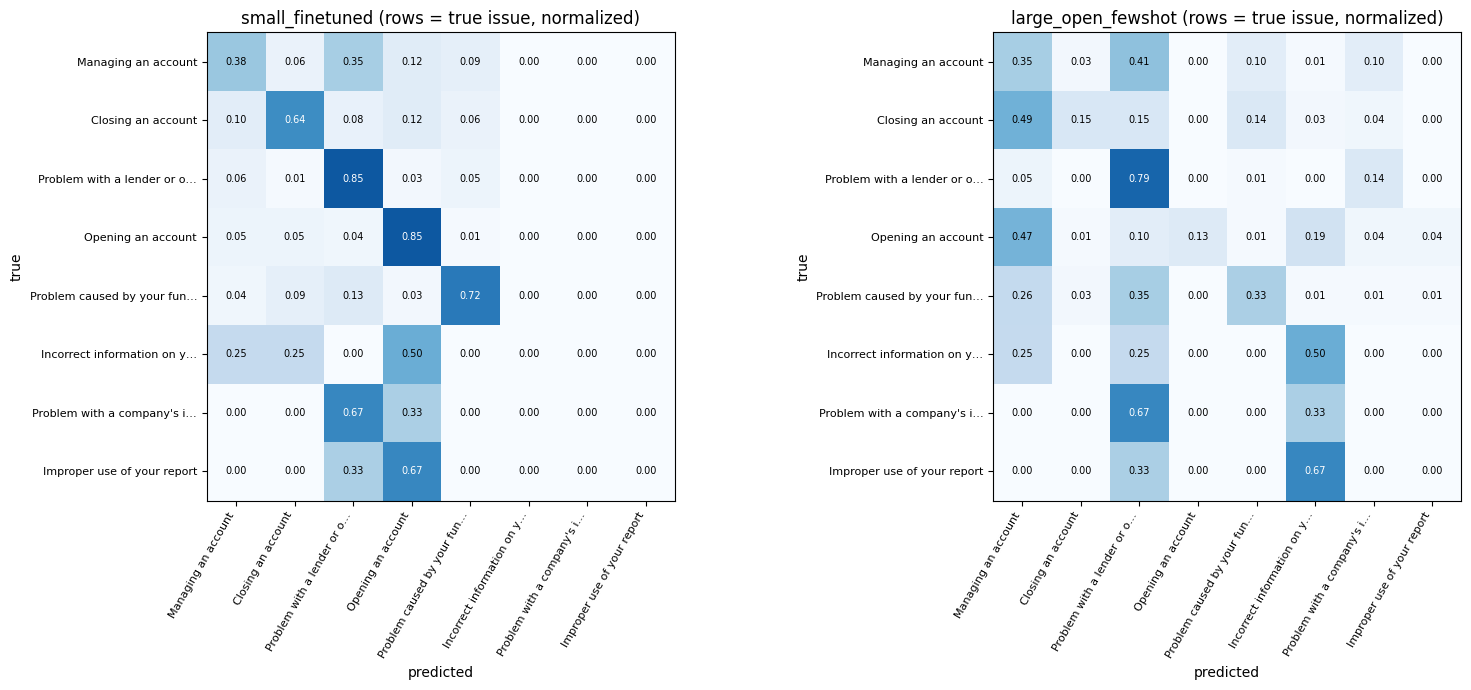

In [17]:
import matplotlib.pyplot as plt

short = [l if len(l) <= 28 else l[:26] + "…" for l in LABELS]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, name in zip(axes, ["small_finetuned", BASELINE_NAME]):
    p = pd.read_csv(f"{RESULTS_DIR}/preds_{name}.csv")
    cm = confusion_matrix(p.label, p.pred, labels=LABELS, normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(LABELS)), short, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(LABELS)), short, fontsize=8)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_title(f"{name} (rows = true issue, normalized)")
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/confusion_matrices.png", dpi=150)
plt.show()

## 8. Error analysis: read these before writing conclusions

In [18]:
# Read IDs as text everywhere, so they match the test set's IDs
read_preds = lambda name: pd.read_csv(f"{RESULTS_DIR}/preds_{name}.csv", dtype={"id": str})
cmp = (read_preds("small_finetuned")[["id", "label", "pred"]]
         .merge(read_preds(BASELINE_NAME)[["id", "pred"]], on="id", suffixes=("_ft", "_frontier"))
         .merge(test[["id", "text"]].astype({"id": str}), on="id"))

ft_only = cmp[(cmp.pred_ft == cmp.label) & (cmp.pred_frontier != cmp.label)]
fr_only = cmp[(cmp.pred_ft != cmp.label) & (cmp.pred_frontier == cmp.label)]
both = cmp[(cmp.pred_ft != cmp.label) & (cmp.pred_frontier != cmp.label)]
print(f"fine-tuned right, baseline wrong: {len(ft_only)} | baseline right, fine-tuned wrong: {len(fr_only)} "
      f"| both wrong: {len(both)}")

def show(frame, title, n=5):
    print(f"\n=== {title} ===")
    for r in frame.head(n).itertuples():
        print(f"\nTRUE: {r.label}\n  fine-tuned: {r.pred_ft}\n  frontier:   {r.pred_frontier}\n  text: {r.text[:400]}…")

show(ft_only, "Fine-tuned right, frontier wrong")
show(fr_only, "Frontier right, fine-tuned wrong")
show(both, "Both wrong (check whether the label itself looks wrong)")

print("\nMost common confusions for the fine-tuned model:")
print(cmp[cmp.pred_ft != cmp.label].groupby(["label", "pred_ft"]).size().sort_values(ascending=False).head(8))

fine-tuned right, baseline wrong: 153 | baseline right, fine-tuned wrong: 24 | both wrong: 108

=== Fine-tuned right, frontier wrong ===

TRUE: Opening an account
  fine-tuned: Opening an account
  frontier:   Managing an account
  text: I opened a business account on XX/XX/year> with this bank. When I met with one of the branch workers to help me open my account .the feeling was already off. Her name is XXXX XXXX. She began to ask me a number of uncomfortable questions as if I came in to request a loan or a credit card. She was asking why KeyBank. How do I plan to manage my receivables etc questions that you will ask if you askin…

TRUE: Problem caused by your funds being low
  fine-tuned: Problem caused by your funds being low
  frontier:   Managing an account
  text: I was told, by an influencer that they had a big lawsuit. I want my portions, so they said to make a complaint with Wells Fargo. When I was married, money constantly came up missing and all the fees we paid.…

TRUE: Pro

## 9. What to put in your write-up

1. **The results table** from section 7, with the 95% confidence intervals. If intervals overlap, say the systems are statistically tied on this test set.
2. **Cost per 1,000 complaints** for each system, with your price assumptions stated, plus training cost (minutes × GPU price) amortized over expected volume.
3. **Per-class results:** which issues the fine-tuned model handles better and which it doesn't.
4. **10 instructive failures** from section 8, including cases where you think the consumer-chosen label is wrong.
5. **When *not* to fine-tune:** low volume, labels that change often, too little labelled data, or when the frontier model is already accurate enough and cheap enough.
6. **Limitations:** noisy self-reported labels, one product only, one random split, US data.

**Next experiments (week 6):** a 3B model, more training data, two epochs, distillation (train on frontier-model labels for unlabelled complaints), and 8-bit vs. 4-bit inference.